---
title: "Combining models"
subtitle: "Choose ensemble members by a stated rule, calibrate each, and average them with construct_mme"
description: "Check which seasonal models are available for September-start OND forecasts, calibrate seven of them with CCA, combine them with PyCPT's construct_mme, and measure what the ensemble changes."
execute:
  enabled: false
---

So far every chapter used one model, CFSv2. PyCPT can calibrate several models
and combine them into a **multi-model ensemble** (MME). This chapter does that
in four steps: decide which models qualify, calibrate each with the same CCA
settings, combine them with `construct_mme`, and measure what the ensemble
changes compared with its members.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment, the case folder from chapters 1 to 3, and internet
access the first time, to download six more models from the IRI Data Library.
Calibrating seven models takes several minutes; the time is printed below.
:::

## 1. Which models qualify?

A model can join this ensemble only if the Data Library has its hindcasts for every
September start from 1991 to 2020 **and** its September 2023 forecast. The rule
was fixed before any skill was computed, so the ensemble is not chosen to look
good.

Ten candidate catalog models were downloaded with `download_data` for exactly this
question, and the result was recorded by this tutorial's
[availability check](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/check_mme_availability.py).
The cell reads that record.

In [1]:
from pathlib import Path
import datetime as dt
import inspect
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import pycpt
from pycpt import notebook as pycpt_notebook

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
sys.path.insert(0, str(repo))
from pycpt_tutorial import figures
figures.use_style()

records = json.loads((repo / "research/audits/learn-pycpt/mme-availability.json").read_text())
table = pd.DataFrame([{
    "model": r["model"],
    "training years missing": ", ".join(map(str, r["missing_training_years"])) or "none",
    "2023 forecast": "yes" if r["forecast_present"] else "no",
    "qualifies": "yes" if (not r["missing_training_years"] and r["forecast_present"]) else "no",
} for r in records]).sort_values(["qualifies", "model"], ascending=[False, True]).set_index("model")
table

,training years missing,2023 forecast,qualifies
model,,,
CCSM4.PRCP,none,yes,yes
CESM1.PRCP,none,yes,yes
CanSIPSIC3.PRCP,none,yes,yes
GEOSS2S.PRCP,none,yes,yes
SEAS51c.PRCP,none,yes,yes
SPEAR.PRCP,none,yes,yes
CanSIPSIC4.PRCP,none,no,no
GCFS2p1.PRCP,"1991, 1992, 2020",yes,no
METEOFRANCE9.PRCP,"1991, 1992",no,no


Six candidates qualify. With CFSv2 from the earlier chapters, the ensemble has
seven members. The table shows why the other four are left out: three of the
Copernicus (C3S) models lack some training years, and two models have no
September 2023 forecast in the catalog (one of them lacks both).

In [2]:
MOS = "CCA"
ensemble = ["CFSv2.PRCP"] + [m for m, row in table.iterrows() if row["qualifies"] == "yes" and m != "CFSv2.PRCP"]
predictor_names = ensemble
predictand_name = "CHIRPS3.PRCP"
download_args = {
    "fdate": dt.datetime(2023, 9, 1),
    "target": "Oct-Dec",
    "target_first_year": 1991,
    "target_final_year": 2020,
    "predictor_extent": {"west": 85, "east": 155, "south": -20, "north": 20},
    "predictand_extent": {"west": 94, "east": 142, "south": -12, "north": 7},
}
cpt_args = {
    "transform_predictand": None, "tailoring": None,
    "cca_modes": (2, 2), "x_eof_modes": (3, 3), "y_eof_modes": (3, 3),
    "validation": "crossvalidation", "drymask_threshold": None, "skillmask_threshold": None,
    "crossvalidation_window": 5, "synchronous_predictors": True,
}
force_download = False

case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = pycpt.setup(case_dir, download_args["predictor_extent"])
local_predictand_file = domain_dir / "data" / "local-CHIRPS3-OND-1991-2020.nc"
print("Ensemble:", ", ".join(ensemble))

Input data will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/output
Ensemble: CFSv2.PRCP, CCSM4.PRCP, CESM1.PRCP, CanSIPSIC3.PRCP, GEOSS2S.PRCP, SEAS51c.PRCP, SPEAR.PRCP


## 2. Load the data and check the years

The availability check already downloaded these files into this case folder for
the same question, so `force_download=False` reuses them; chapter 1 explains why
that is safe only when the folder and question match. `summarize_available_years`
confirms the training years for every member.

In [3]:
Y, hindcast_data, forecast_data = pycpt.download_data(
    predictand_name, local_predictand_file, predictor_names, download_args, domain_dir, force_download)
pycpt.summarize_available_years(predictor_names, predictand_name, download_args, Y, hindcast_data, forecast_data)

Reusing already-downloaded CFSv2.PRCP_f2023

Reusing already-downloaded CCSM4.PRCP_f2023

Reusing already-downloaded CESM1.PRCP_f2023



Reusing already-downloaded CanSIPSIC3.PRCP_f2023

Reusing already-downloaded GEOSS2S.PRCP_f2023

Reusing already-downloaded SEAS51c.PRCP_f2023



Reusing already-downloaded SPEAR.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Reusing already-downloaded CCSM4.PRCP

Reusing already-downloaded CESM1.PRCP

Reusing already-downloaded CanSIPSIC3.PRCP

Reusing already-downloaded GEOSS2S.PRCP

Reusing already-downloaded SEAS51c.PRCP

Reusing already-downloaded SPEAR.PRCP



,CHIRPS3.PRCP,CFSv2.PRCP,CCSM4.PRCP,CESM1.PRCP,CanSIPSIC3.PRCP,GEOSS2S.PRCP,SEAS51c.PRCP,SPEAR.PRCP
1991,ok,ok,ok,ok,ok,ok,ok,ok
1992,ok,ok,ok,ok,ok,ok,ok,ok
1993,ok,ok,ok,ok,ok,ok,ok,ok
1994,ok,ok,ok,ok,ok,ok,ok,ok
1995,ok,ok,ok,ok,ok,ok,ok,ok
1996,ok,ok,ok,ok,ok,ok,ok,ok
1997,ok,ok,ok,ok,ok,ok,ok,ok
1998,ok,ok,ok,ok,ok,ok,ok,ok
1999,ok,ok,ok,ok,ok,ok,ok,ok
2000,ok,ok,ok,ok,ok,ok,ok,ok


,CFSv2.PRCP,CCSM4.PRCP,CESM1.PRCP,CanSIPSIC3.PRCP,GEOSS2S.PRCP,SEAS51c.PRCP,SPEAR.PRCP
2023,ok,ok,ok,ok,ok,ok,ok


## 3. Calibrate every member the same way

`evaluate_models` takes the whole list and fits CCA to each model in turn, with
the settings of chapter 4. Each member is calibrated against the same CHIRPS v3.0
observations, so every member's output is on the same 0.25° grid and in the same
units, which is what makes averaging them possible.

In [4]:
start = time.monotonic()
hcsts, fcsts, skill, pxs, pys = pycpt.evaluate_models(
    hindcast_data, MOS, Y, forecast_data, cpt_args, domain_dir, predictor_names)
print(f"Calibrated {len(predictor_names)} models in {time.monotonic() - start:.0f} s")

Calibrated 7 models in 248 s


## 4. What `construct_mme` does

Read it before using it. In PyCPT 2.10.4, `construct_mme` calls
`construct_mme_new` and then `evaluate_mme`. The key lines of `construct_mme_new`:

In [5]:
source = inspect.getsource(pycpt_notebook.construct_mme_new).splitlines()
for number, line in enumerate(source, start=1):
    if any(word in line for word in ["fillna", ".mean('model')", "climo_prob =", "climo_var =", "climo_mu ="]):
        print(f"{number:4d} | {line}")

  23 |     climo_mu = mu.mean('T')
  24 |     hcsts_ds['deterministic'] = mu.fillna(climo_mu)
  27 |     climo_var = mu.var('T') # variance of the deterministic forecast
  28 |     hcsts_ds['prediction_error_variance'] = var.fillna(climo_var)
  30 |     climo_prob = xr.DataArray([33, 34, 33], coords={'C': ['1', '2', '3']})
  31 |     hcsts_ds['probabilistic'] = hcsts_ds['probabilistic'].fillna(climo_prob)
  33 |     mme_hcst = hcsts_ds.mean('model')
  71 |         .fillna(xr.Dataset({
  76 |         .mean('model')


So the ensemble is an **equal-weight average** of the calibrated members, taken
separately for the deterministic forecast, the prediction-error variance and the
three category probabilities. A member with a missing value contributes
climatology instead: its training mean, its hindcast variance or 33/34/33%.
The ensemble probabilities are therefore averages of the members' probabilities;
they are not recomputed from the averaged forecast.

`evaluate_mme` then scores the averaged hindcasts. The deterministic hindcasts are
averages of cross-validated hindcasts, so their scores are cross-validated. The
probabilistic hindcasts are averages of the members' **in-sample** probabilities
(chapter 4, step 2), so the probabilistic scores inherit that optimism.

In [6]:
mme_det, mme_prob, mme_pev, mme_skill = pycpt.construct_mme(
    fcsts, hcsts, Y, ensemble, predictor_names, cpt_args, domain_dir)

cells = Y.notnull().all("T")
member_det = xr.concat([f.deterministic for f in fcsts], dim="model").mean("model")
member_prob = xr.concat([f.probabilistic for f in fcsts], dim="model").mean("model")
print("Ensemble forecast minus mean of members, largest difference:",
      float(abs(mme_det - member_det).where(cells).max()), "mm")
print("Ensemble probabilities minus mean of members, largest difference:",
      float(abs(mme_prob - member_prob).where(cells).max()), "percentage points")
print("Files written:", sorted(p.name for p in (domain_dir / "output").glob("MME_*")))

Ensemble forecast minus mean of members, largest difference: 0.0 mm
Ensemble probabilities minus mean of members, largest difference: 0.0 percentage points
Files written: ['MME_deterministic_forecast_2023.nc', 'MME_deterministic_hindcasts.nc', 'MME_forecast_prediction_error_variance_2023.nc', 'MME_hindcast_prediction_error_variance.nc', 'MME_probabilistic_forecast_2023.nc', 'MME_probabilistic_hindcasts.nc', 'MME_skill_scores.nc']


## 5. Did combining help? Cross-validated skill

The fair comparison uses the cross-validated deterministic hindcasts, 1991-2020,
over the 3,240 Indonesian cells. Two summaries per forecast: the error (RMSE,
area-weighted, pooled over the 30 seasons) and the median of the cell-by-cell
Pearson correlations that CPT reports.

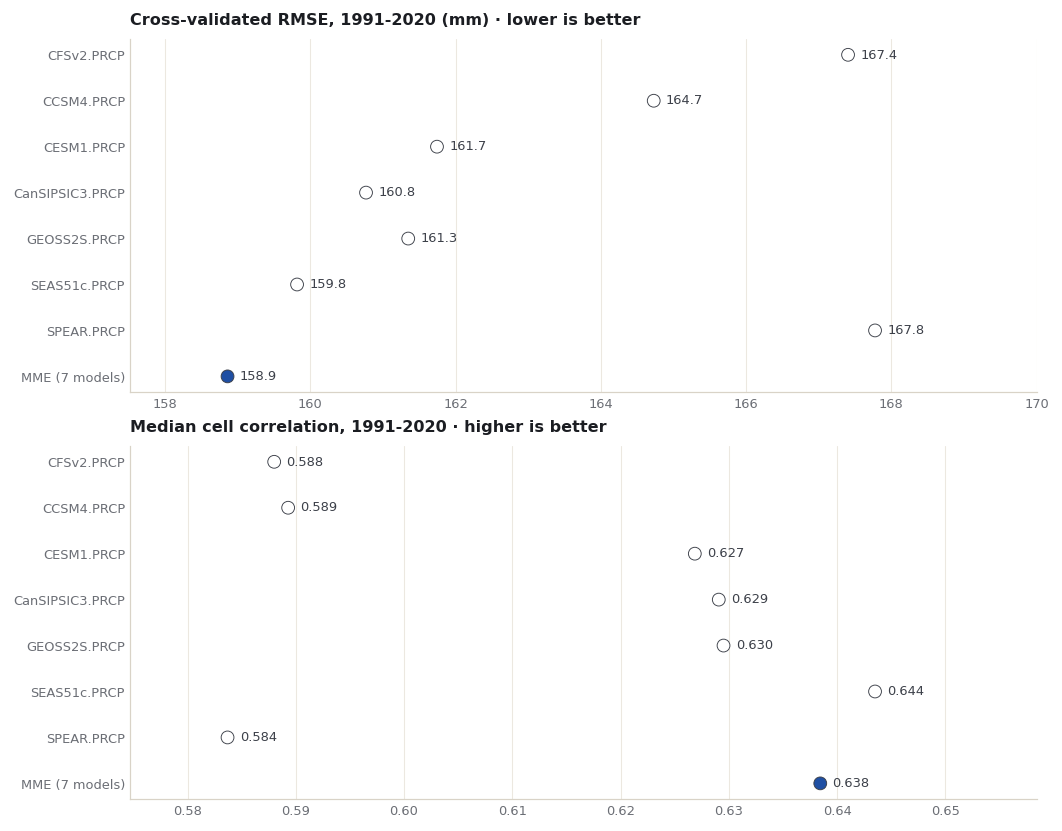

,CV RMSE (mm),median Pearson
forecast,,
CFSv2.PRCP,167.403,0.588
CCSM4.PRCP,164.727,0.589
CESM1.PRCP,161.743,0.627
CanSIPSIC3.PRCP,160.766,0.629
GEOSS2S.PRCP,161.347,0.630
SEAS51c.PRCP,159.817,0.644
SPEAR.PRCP,167.775,0.584
MME (7 models),158.859,0.638


In [7]:
weights = np.cos(np.deg2rad(Y["Y"])) * cells
ensemble_cv = xr.concat([h.deterministic for h in hcsts], dim="model").mean("model")


def pooled_rmse(hindcast):
    error = (hindcast - Y).where(cells)
    return float(np.sqrt((error ** 2).weighted(weights).mean(("Y", "X")).mean("T")))


rows = [{"forecast": name, "CV RMSE (mm)": pooled_rmse(h.deterministic),
         "median Pearson": float(s.pearson.where(cells).median())}
        for name, h, s in zip(predictor_names, hcsts, skill)]
rows.append({"forecast": "MME (7 models)", "CV RMSE (mm)": pooled_rmse(ensemble_cv),
             "median Pearson": float(mme_skill.pearson.where(mme_skill.pearson > -999).where(cells).median())})
cv_table = pd.DataFrame(rows).set_index("forecast")

fig, grid = figures.stacked([3.2, 3.2], width=9.5)
colours = [figures.ACCENT if name.startswith("MME") else "white" for name in cv_table.index]
for row, column, label in [(0, "CV RMSE (mm)", "Cross-validated RMSE, 1991-2020 (mm) · lower is better"),
                           (1, "median Pearson", "Median cell correlation, 1991-2020 · higher is better")]:
    ax = fig.add_subplot(grid[row, 0])
    y = np.arange(len(cv_table))
    ax.scatter(cv_table[column], y, s=70, color=colours, edgecolor=figures.INK_2, linewidth=0.6, zorder=3)
    for yy, value in zip(y, cv_table[column]):
        ax.annotate(f"{value:.3f}" if column.startswith("median") else f"{value:.1f}", (value, yy),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=figures.INK_2)
    ax.set_yticks(y, cv_table.index)
    ax.set_title(label)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    span = cv_table[column].max() - cv_table[column].min()
    ax.set_xlim(cv_table[column].min() - 0.15 * span, cv_table[column].max() + 0.25 * span)
plt.show()
cv_table.round(3)

Read the numbers above before reading this paragraph. In this case the ensemble
has the lowest cross-validated RMSE of all eight forecasts, but not the highest
median correlation, and the differences between the best members and the ensemble
are small. Averaging reduces the error without making the ensemble better than
every member on every measure.

The dots are drawn on a scale that spans only the range of the eight values, so
small differences look large; read the printed numbers. The maps show where the
correlation changed, comparing the ensemble with CFSv2. In the third map, purple
means the ensemble's correlation is higher.

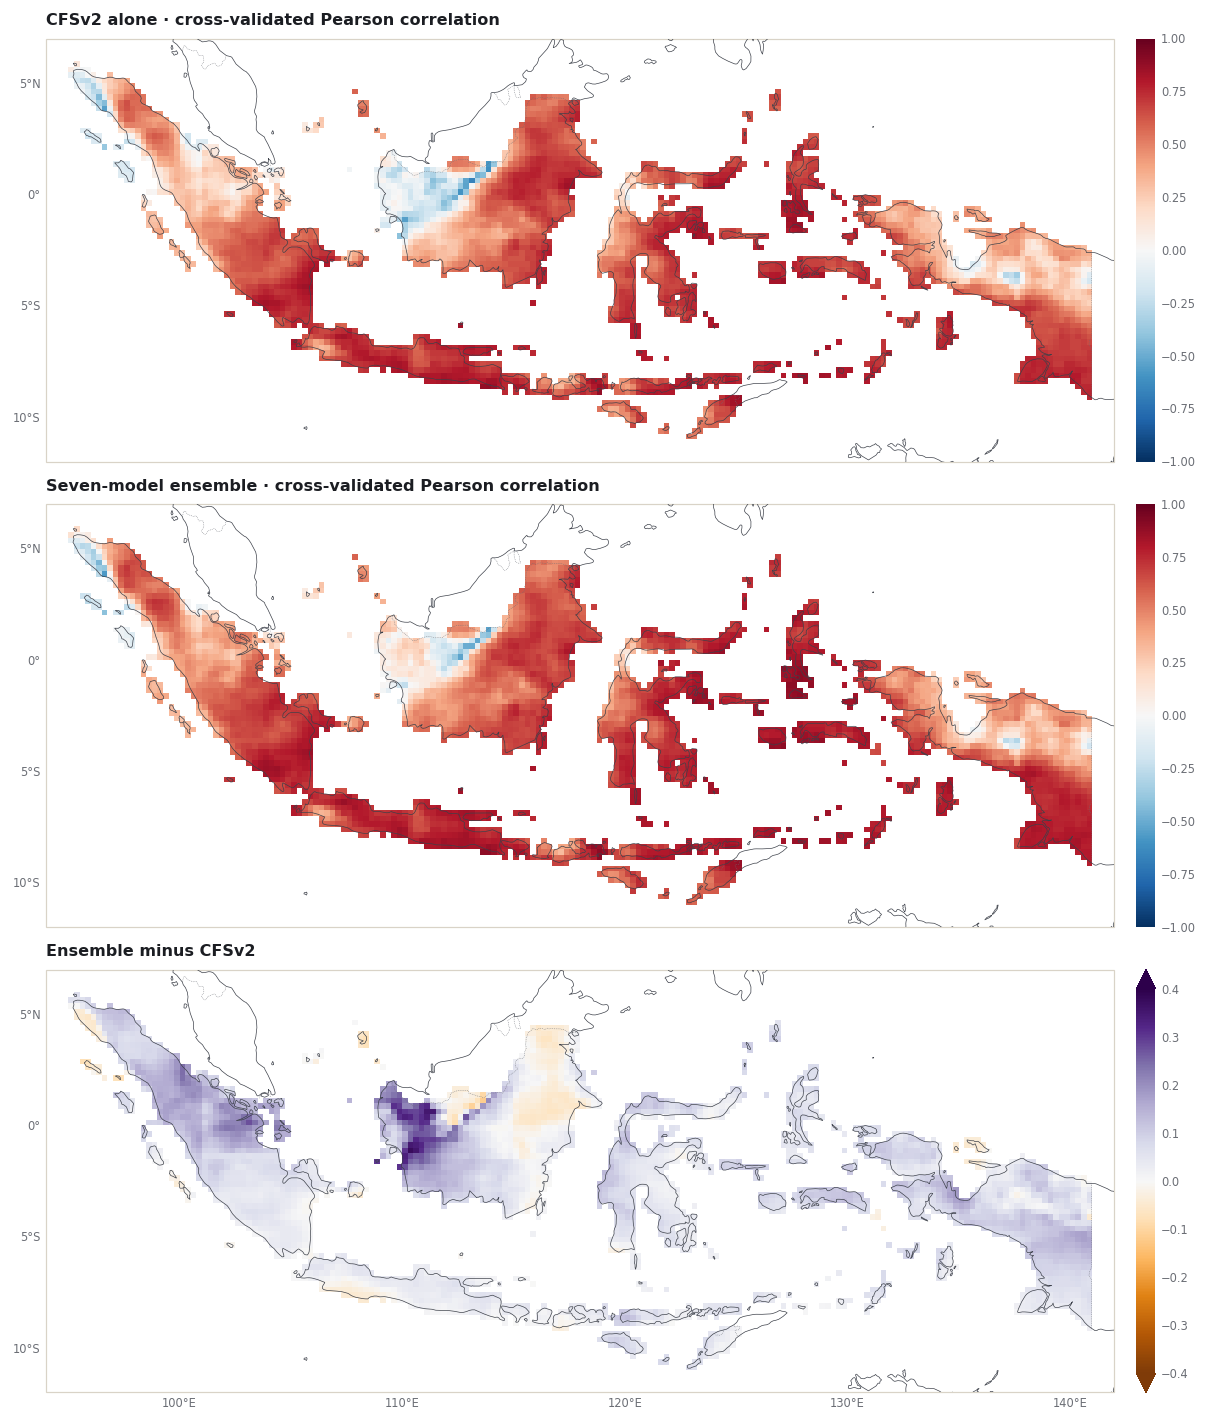

Cells where the ensemble correlation is higher than CFSv2's: 87.8%


In [8]:
predictand_box = figures.extent_of(download_args["predictand_extent"])
cfs_pearson = skill[0].pearson.where(cells)
mme_pearson = mme_skill.pearson.where(mme_skill.pearson > -999).where(cells)

fig, grid = figures.stacked([figures.map_height(predictand_box)] * 3)
for row, (field, title, cmap, low, high) in enumerate([
        (cfs_pearson, "CFSv2 alone · cross-validated Pearson correlation", "RdBu_r", -1, 1),
        (mme_pearson, "Seven-model ensemble · cross-validated Pearson correlation", "RdBu_r", -1, 1),
        (mme_pearson - cfs_pearson, "Ensemble minus CFSv2", "PuOr", -0.4, 0.4)]):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == 2)
    image = figures.draw_field(ax, field, cmap=cmap, vmin=low, vmax=high)
    ax.set_title(title)
    figures.colorbar(fig, image, ax, "", extend="both" if row == 2 else "neither")
plt.show()
print(f"Cells where the ensemble correlation is higher than CFSv2's: "
      f"{float(((mme_pearson - cfs_pearson) > 0).sum() / cells.sum() * 100):.1f}%")

## 6. The ensemble forecast for OND 2023

The same two maps as in chapter 4, now for the ensemble. The most-likely-category
rule and colour ranges are PyCPT's own (chapter 4, step 7).

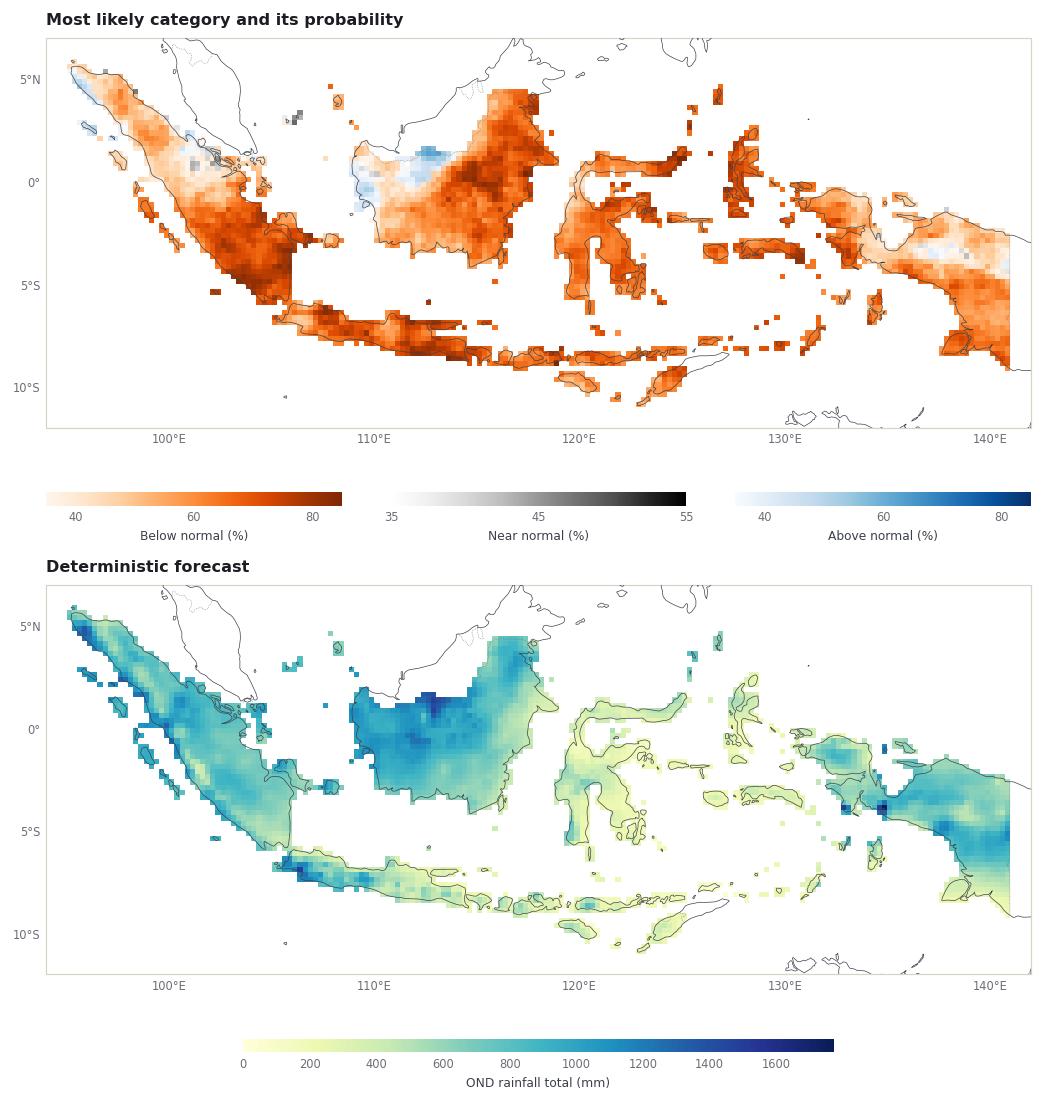

Members whose most likely category matches the ensemble's, share of cells (%):
0     0.0
1     0.0
2     0.3
3     0.9
4     1.5
5     3.8
6    30.7
7    62.8


In [9]:
mme_forecast = xr.Dataset({"deterministic": mme_det, "probabilistic": mme_prob})
figures.forecast_figure(mme_forecast, predictand_box)
plt.show()

leading = [f.probabilistic.isel(T=0).fillna(-1).argmax("C").where(cells) for f in fcsts]
mme_leading = mme_prob.isel(T=0).fillna(-1).argmax("C").where(cells)
agreeing = sum((lead == mme_leading).astype(int) for lead in leading).where(cells)
print("Members whose most likely category matches the ensemble's, share of cells (%):")
print(pd.Series({n: round(float((agreeing == n).sum() / cells.sum() * 100), 1) for n in range(len(fcsts) + 1)}).to_string())

In most cells the members agree with the ensemble's most likely category: the
last two rows above count the cells where six or all seven members do. Where
fewer agree, the ensemble's leading category rests on a split between models.

## 7. One season: how did each forecast do in 2023?

The observed OND 2023 totals (CHIRPS v3.0, from the Fit & diagnose case) give one
more comparison. As in chapter 5, one season is a description, not a skill test.

In [10]:
context = xr.open_dataset(repo / "docs/data/fitting-2023/comparison-context.nc")
observed = context.observed_rainfall.sel(season="OND").reset_coords(drop=True)


def rmse_2023(forecast):
    error = (forecast.isel(T=0) - observed).where(cells)
    return float(np.sqrt((error ** 2).weighted(weights).mean(("Y", "X"))))


season_table = pd.DataFrame(
    [{"forecast": n, "2023 RMSE (mm)": rmse_2023(f.deterministic)} for n, f in zip(predictor_names, fcsts)]
    + [{"forecast": "MME (7 models)", "2023 RMSE (mm)": rmse_2023(mme_det)}]).set_index("forecast")
season_table.round(1)

,2023 RMSE (mm)
forecast,
CFSv2.PRCP,124.1
CCSM4.PRCP,129.4
CESM1.PRCP,126.5
CanSIPSIC3.PRCP,124.1
GEOSS2S.PRCP,141.8
SEAS51c.PRCP,131.2
SPEAR.PRCP,176.1
MME (7 models),131.6


In 2023 the ensemble's error sits among its members' errors rather than below all
of them. A single season can favour any member; the 30-season cross-validated
comparison above is the stronger evidence, and even that is limited to this
domain, season and setup.

## What you have now

- A stated rule for choosing ensemble members, and the evidence for each candidate.
- Seven models calibrated with identical settings by `evaluate_models`.
- `construct_mme` read and checked: an equal-weight mean of the calibrated members,
  with in-sample probabilistic scores.
- A measured comparison: lowest cross-validated error for the ensemble, but not the
  best on every measure or in every season.

The next chapter collects what changes when you adapt this workflow to your own
region and season.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
3. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
4. PyCPT Tutorial. *Model availability check* (research/scripts/check_mme_availability.py) and its record (research/audits/learn-pycpt/mme-availability.json). <https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/check_mme_availability.py>
5. IRI Data Library. *North American Multi-Model Ensemble (NMME)* collection. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Kirtman, B., Min, D., Infanti, J., et al. (2014). The North American Multimodel Ensemble: Phase-1 seasonal-to-interannual prediction; Phase-2 toward developing intraseasonal prediction. *Bulletin of the American Meteorological Society*, 95(4), 585-601. <https://doi.org/10.1175/BAMS-D-12-00050.1>
7. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
8. IRI Data Library. *Copernicus C3S ECMWF SEAS5.1* (catalog entry SEAS51c). <https://iridl.ldeo.columbia.edu/SOURCES/.EU/.Copernicus/.CDS/.C3S/.ECMWF/.SEAS51_iri2/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
9. Johnson, S., Stockdale, T., Ferranti, L., et al. (2019). SEAS5: the new ECMWF seasonal forecast system. *Geoscientific Model Development*, 12, 1087-1117. <https://doi.org/10.5194/gmd-12-1087-2019>
10. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
11. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
12. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
13. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>